In [3]:
import pandas as pd 
df = pd.read_csv(
    r"S:\DA  notes\census+income\adult.data",
    header=None,
    skipinitialspace=True
)

df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [4]:
import pandas as pd

df = pd.read_csv(
    r"S:\DA  notes\E_Comm_dataset.csv"
)

df

,user_ID,Name,Age,Gender,City,Education_Level,Monthly_Income,Marrige_Status,Date_of_order,Product_order_count,Order_Amount_INR,Wallet_Balance_INR,Total_Order_INR
0,1.0,NaN,NaN,Female,NaN,Graduate,52860.0,Single,10-03-2023,4.0,NaN,21822.0,23134.0
1,2.0,NaN,26.0,Male,Delhi,Graduate,NaN,Single,14-04-2024,1.0,20495.0,17493.0,19110.0
2,3.0,Anjali Agarwal,27.0,Female,Delhi,10th,25753.0,Single,NaN,3.0,6057.0,13325.0,14916.0
3,4.0,NaN,20.0,Female,NaN,Graduate,NaN,Divorced,27-02-2024,4.0,3171.0,11955.0,11995.0
4,5.0,Arjun Jain,28.0,Male,Delhi,Graduate,35921.0,NaN,24-05-2024,1.0,6695.0,3063.0,6242.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,249996.0,NaN,25.0,Male,Ahmedabad,NaN,50311.0,Single,19-08-2025,3.0,5632.0,19736.0,16007.0
249996,249997.0,NaN,28.0,Female,Mumbai,Postgrad,102046.0,Single,21-02-2025,4.0,8234.0,35957.0,31567.0
249997,249998.0,NaN,36.0,Male,Pune,Postgrad,73974.0,Single,11-12-2023,5.0,6235.0,28732.0,31747.0
249998,249999.0,NaN,37.0,Male,Ahmedabad,Graduate,44424.0,Single,19-04-2024,1.0,108.0,16522.0,100.0


####  Handling outlier using Z-score

In [5]:
# Interview Question : Do Categorical columns can have Outerliers ?
# Yes Categorical column can have Outliers

In [6]:
df

,user_ID,Name,Age,Gender,City,Education_Level,Monthly_Income,Marrige_Status,Date_of_order,Product_order_count,Order_Amount_INR,Wallet_Balance_INR,Total_Order_INR
0,1.0,NaN,NaN,Female,NaN,Graduate,52860.0,Single,10-03-2023,4.0,NaN,21822.0,23134.0
1,2.0,NaN,26.0,Male,Delhi,Graduate,NaN,Single,14-04-2024,1.0,20495.0,17493.0,19110.0
2,3.0,Anjali Agarwal,27.0,Female,Delhi,10th,25753.0,Single,NaN,3.0,6057.0,13325.0,14916.0
3,4.0,NaN,20.0,Female,NaN,Graduate,NaN,Divorced,27-02-2024,4.0,3171.0,11955.0,11995.0
4,5.0,Arjun Jain,28.0,Male,Delhi,Graduate,35921.0,NaN,24-05-2024,1.0,6695.0,3063.0,6242.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,249996.0,NaN,25.0,Male,Ahmedabad,NaN,50311.0,Single,19-08-2025,3.0,5632.0,19736.0,16007.0
249996,249997.0,NaN,28.0,Female,Mumbai,Postgrad,102046.0,Single,21-02-2025,4.0,8234.0,35957.0,31567.0
249997,249998.0,NaN,36.0,Male,Pune,Postgrad,73974.0,Single,11-12-2023,5.0,6235.0,28732.0,31747.0
249998,249999.0,NaN,37.0,Male,Ahmedabad,Graduate,44424.0,Single,19-04-2024,1.0,108.0,16522.0,100.0


#### Z-score

In [7]:
# def: how much standard deviation the data is far away from the mean.
# z_score =(data-mean)/SD

In [10]:
# Definition: Displays all column names in the DataFrame.
# Importance: Helps us find the correct age column.
# Point 1: Column names are case-sensitive.
# Point 2: 'Age' and 'age' are different.

df.columns

Index(['user_ID', 'Name', 'Age', 'Gender', 'City', 'Education_Level',
       'Monthly_Income', 'Marrige_Status', 'Date_of_order',
       'Product_order_count', 'Order_Amount_INR', 'Wallet_Balance_INR',
       'Total_Order_INR'],
      dtype='object')

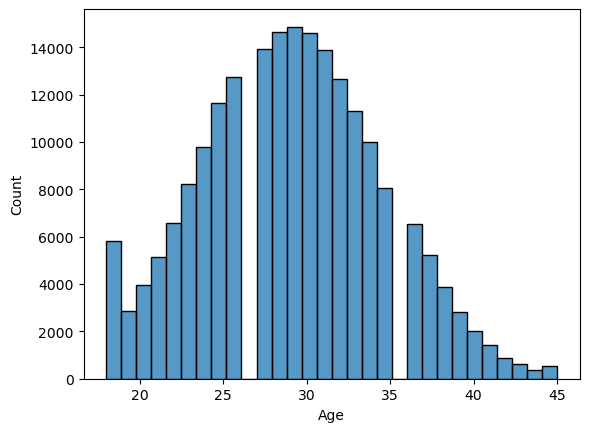

In [12]:
# Definition: Displays the distribution of age values.
# Importance: Helps us understand the age distribution and check its shape.
# Point 1: x='Age' uses the correct column name.
# Point 2: bins=30 divides the data into 30 intervals.

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x='Age', bins=30)
plt.show()

In [14]:
# Definition: Calculates the Z-score for each age value.
# Importance: Helps identify potential outliers in normally distributed data.
# Point 1: Mean is the average age.
# Point 2: Standard deviation measures how spread out the ages are.

df6 = df.copy()

df6["z-score"] = (df6["Age"] - df6["Age"].mean()) / df6["Age"].std()

df6

,user_ID,Name,Age,Gender,City,Education_Level,Monthly_Income,Marrige_Status,Date_of_order,Product_order_count,Order_Amount_INR,Wallet_Balance_INR,Total_Order_INR,z-score
0,1.0,NaN,NaN,Female,NaN,Graduate,52860.0,Single,10-03-2023,4.0,NaN,21822.0,23134.0,NaN
1,2.0,NaN,26.0,Male,Delhi,Graduate,NaN,Single,14-04-2024,1.0,20495.0,17493.0,19110.0,-0.561700
2,3.0,Anjali Agarwal,27.0,Female,Delhi,10th,25753.0,Single,NaN,3.0,6057.0,13325.0,14916.0,-0.376365
3,4.0,NaN,20.0,Female,NaN,Graduate,NaN,Divorced,27-02-2024,4.0,3171.0,11955.0,11995.0,-1.673709
4,5.0,Arjun Jain,28.0,Male,Delhi,Graduate,35921.0,NaN,24-05-2024,1.0,6695.0,3063.0,6242.0,-0.191030
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,249996.0,NaN,25.0,Male,Ahmedabad,NaN,50311.0,Single,19-08-2025,3.0,5632.0,19736.0,16007.0,-0.747035
249996,249997.0,NaN,28.0,Female,Mumbai,Postgrad,102046.0,Single,21-02-2025,4.0,8234.0,35957.0,31567.0,-0.191030
249997,249998.0,NaN,36.0,Male,Pune,Postgrad,73974.0,Single,11-12-2023,5.0,6235.0,28732.0,31747.0,1.291648
249998,249999.0,NaN,37.0,Male,Ahmedabad,Graduate,44424.0,Single,19-04-2024,1.0,108.0,16522.0,100.0,1.476983


In [15]:
# Definition: Filters records where the Z-score is above +3 or below -3.
# Importance: Helps identify potential outliers in the Age column.
# Point 1: > +3 identifies unusually high values.
# Point 2: < -3 identifies unusually low values.

outliers = df6[(df6["z-score"] > +3) | (df6["z-score"] < -3)]
outliers

,user_ID,Name,Age,Gender,City,Education_Level,Monthly_Income,Marrige_Status,Date_of_order,Product_order_count,Order_Amount_INR,Wallet_Balance_INR,Total_Order_INR,z-score


In [16]:
df6[(df6["z-score"]>-3)&(df6["z-score"]<+3)]

,user_ID,Name,Age,Gender,City,Education_Level,Monthly_Income,Marrige_Status,Date_of_order,Product_order_count,Order_Amount_INR,Wallet_Balance_INR,Total_Order_INR,z-score
1,2.0,NaN,26.0,Male,Delhi,Graduate,NaN,Single,14-04-2024,1.0,20495.0,17493.0,19110.0,-0.561700
2,3.0,Anjali Agarwal,27.0,Female,Delhi,10th,25753.0,Single,NaN,3.0,6057.0,13325.0,14916.0,-0.376365
3,4.0,NaN,20.0,Female,NaN,Graduate,NaN,Divorced,27-02-2024,4.0,3171.0,11955.0,11995.0,-1.673709
4,5.0,Arjun Jain,28.0,Male,Delhi,Graduate,35921.0,NaN,24-05-2024,1.0,6695.0,3063.0,6242.0,-0.191030
5,6.0,NaN,34.0,NaN,Kolkata,12th,34151.0,Single,04-03-2024,2.0,6706.0,11755.0,14534.0,0.920978
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,249996.0,NaN,25.0,Male,Ahmedabad,NaN,50311.0,Single,19-08-2025,3.0,5632.0,19736.0,16007.0,-0.747035
249996,249997.0,NaN,28.0,Female,Mumbai,Postgrad,102046.0,Single,21-02-2025,4.0,8234.0,35957.0,31567.0,-0.191030
249997,249998.0,NaN,36.0,Male,Pune,Postgrad,73974.0,Single,11-12-2023,5.0,6235.0,28732.0,31747.0,1.291648
249998,249999.0,NaN,37.0,Male,Ahmedabad,Graduate,44424.0,Single,19-04-2024,1.0,108.0,16522.0,100.0,1.476983


In [17]:
df.shape

(250000, 13)

In [18]:
# interview Question: when to apply the IQR method or z_score method to handle outlier?
# z_score method works nice when data is normal distribution
# IQR method is used when data is skewed

In [19]:
## Clipping Method

In [20]:
# clip do not delete the outlier
# winsorization method

In [22]:
# Definition: Finds the smallest value in the Age column.
# Importance: Helps identify the youngest age in the dataset.
# Point 1: min() returns the smallest value.
# Point 2: Column names must match exactly.

df['Age'].min()

18.0

In [23]:
 # Definition: Finds the highest value in the Age column.
# Importance: Helps identify the oldest age in the dataset.
# Point 1: max() returns the largest value.
# Point 2: Column names are case-sensitive.

df['Age'].max()

45.0

In [24]:
# Definition: Restricts Age values to the range 18–60.
# Importance: Limits extreme values without removing rows.
# Point 1: Values below 18 become 18.
# Point 2: Values above 60 become 60.

df7 = df.copy()
df7['Age'] = df7['Age'].clip(lower=18, upper=60)
df7['Age'].unique()

array([nan, 26., 27., 20., 28., 34., 30., 24., 33., 35., 40., 23., 36.,
       19., 32., 29., 38., 31., 22., 25., 18., 39., 37., 42., 21., 41.,
       45., 43., 44.])

In [25]:
df7.shape

(250000, 13)

In [28]:
# in clip() method we don't delete the records
# smaller values than "lower" will become equal to "lower".e.g 17,18,19=20
# upper values=80

In [29]:
# Definition: Winsorization limits extreme values using specified percentages.
# Importance: Helps reduce the effect of outliers without deleting rows.
# Point 1: limits=(0.05, 0.05) clips the lowest 5% and highest 5%.
# Point 2: The original DataFrame remains unchanged because we use df.copy().

from scipy.stats.mstats import winsorize

df8 = df.copy()
df8['Age'] = winsorize(df8['Age'], limits=(0.05, 0.05))
df8['Age'].unique()

array([nan, 26., 27., 20., 28., 34., 30., 24., 33., 35., 40., 23., 36.,
       32., 29., 38., 31., 22., 25., 39., 37., 42., 21., 41., 45., 43.,
       44.])